### **Synthetic Data**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.gmm import GMM
from src.knn import KNN
from src.lda import LDA
from src.pca import PCA
from src.svm import SVM
from src.plotting import plot_pca_2d


### **Load Data**

In [2]:
import pickle

with open("./data/synthetic/data.pkl", "rb") as file:
    data = pickle.load(file)
X = data["x"]
y = data["y"]

print(X.shape)
print(y.shape)

(20000, 16)
(20000,)


### **Shuffle and Split**

In [3]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(y))
X = X[indices]
y = y[indices]

train_end = int(0.6 * len(y))
val_end = int(0.8 * len(y))
X_train = X[:train_end]
y_train = y[:train_end]
X_val = X[train_end:val_end]
y_val = y[train_end:val_end]
X_test = X[val_end:]
y_test = y[val_end:]


In [4]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [0 1]
Train: (12000, 16)
Validation: (4000, 16)
Test: (4000, 16)


### **2D PCA Visualization**

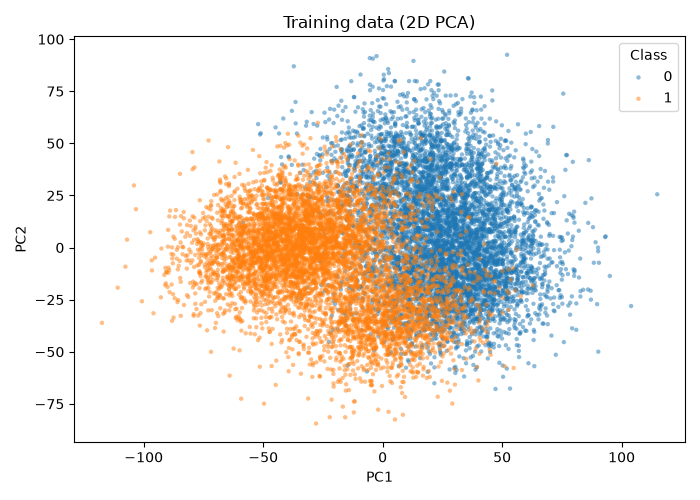

In [5]:
plot_pca_2d(X_train, y_train)


### **GMM**

In [6]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 3
Class 1 EM iterations: 73


In [7]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [8]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 1.0
Test accuracy: 1.0
Test confusion matrix:
 [[2001    0]
 [   0 1999]]


### **KNN**

In [9]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [10]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.99475
Test accuracy: 0.99575
Test confusion matrix:
 [[1985   16]
 [   1 1998]]


### **LDA**

In [11]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [12]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.945
Test accuracy: 0.94775
Test confusion matrix:
 [[1880  121]
 [  88 1911]]


### **SVM**

In [13]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 1
Gaussian sigma: 38.0489529834744
Converged: True
Largest KKT gap: 0.0009988472866491183


In [14]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.99675
Test accuracy: 0.9975
Test confusion matrix:
 [[1995    6]
 [   4 1995]]


### **PCA**

In [15]:
K = 8
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (12000, 8)
Validation: (4000, 8)
Test: (4000, 8)


### **GMM with PCA**

In [16]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 5
Class 1 EM iterations: 13


In [17]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [18]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.984
Test accuracy: 0.98325
Test confusion matrix:
 [[1962   39]
 [  28 1971]]


### **KNN with PCA**

In [19]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [20]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.973
Test accuracy: 0.9785
Test confusion matrix:
 [[1947   54]
 [  32 1967]]


### **LDA with PCA**

In [21]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [22]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.91075
Test accuracy: 0.9075
Test confusion matrix:
 [[1839  162]
 [ 208 1791]]


### **SVM with PCA**

In [23]:
svm_pca = SVM(max_iter=1000000)
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 1
Gaussian sigma: 32.91673994386302
Converged: True
Largest KKT gap: 0.0009971884098831651


In [24]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.96375
Test accuracy: 0.964
Test confusion matrix:
 [[1931   70]
 [  74 1925]]


### **Accuracy Comparison**

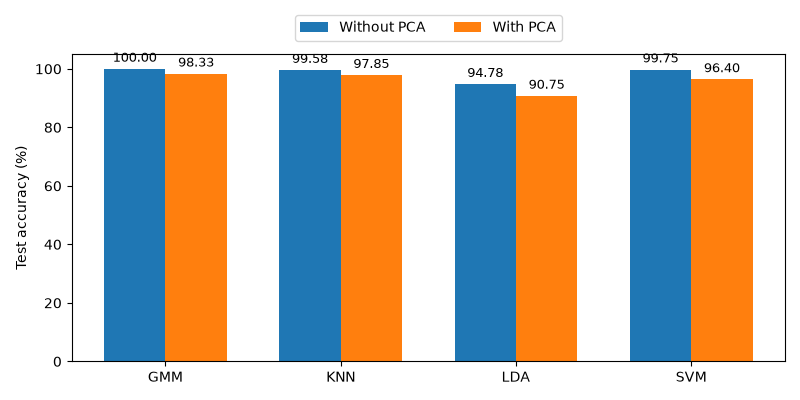

In [25]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()
